![Banner](../../../../Images/Banner/07_remote_sensing/09_13_banner_rs_capstones.png)


# Field Edge Detection across Four Countries: Training in Mexico, Mali, Cambodia and Bangladesh, Testing on an Unseen Bangladesh Site

Notebook 09_10_03 repeated the field-unit study of Yang et al. (2020) on one WorldView scene from Patuakhali, Bangladesh.


## Overview

There, the models were trained and tested on tiles cut from the same village. That leaves an open question: does a boundary detector trained on some landscapes find fields in a place it has never seen?

This capstone asks that question with five very-high-resolution images from four countries (`Data/08_remote_sensing/08_11_Capstones/Edge_detection_global_data`), each with hand-digitised field-boundary lines:

| Site | Country | Image | Role |
|---|---|---|---|
| `mexico` | Mexico | 0.125 m RGB, terraced hill farms between forest | training and validation |
| `mali` | Mali | 2 m WorldView (8 bands), large rain-fed fields with trees | training and validation |
| `cambodia` | Cambodia | 0.17 m RGB, rice paddies and villages | training and validation |
| `babuganj` | Bangladesh (site 1) | 0.1 m drone RGB + NIR, small paddy plots | training and validation |
| `chandpasha` | Bangladesh (site 2) | 0.06 m drone RGB + NIR, small paddy plots | **independent test**, never used for any choice |

One site per country is used for training and validation. The second Bangladesh site, Chandpasha, is held out completely. It is scored once, at the end, with settings chosen on the other four sites.

The methods are those of 09_10_03 (and of the paper), with the tools in `geolattice.rsense.edge_detectors`:

| Paper / 09_10_03 | This notebook | GeoLattice |
|---|---|---|
| Field outlines buffered by 0.5 m and rasterised at 0.5 m: boundary vs non-boundary | Step 2 | `ed.rasterize_boundaries` |
| 192 x 192 tiles, rotation augmentation | Step 3 | `ed.tile_pairs`, `ed.dihedral_augment` |
| Precision, recall, F1 of the boundary class, ROC and AUC | Steps 4 and 8 | `ed.edge_metrics`, `ed.select_threshold` |
| Roberts, Sobel, Prewitt, LoG, Canny | Step 5 | `ed.classical_edges` |
| Random forest, 600 trees, depth 30, LBP and GLCM texture | Step 6 | `texture.lbp_texture`, `texture.glcm_texture` |
| U-Net, SegNet, FC-DenseNet56/67/103, FCN-DKConv6 | Step 7 | `ed.build_edge_model`, `ic.train_model` |
| Learning-rate sensitivity (Table 6) | Step 7b | `ic.train_model` |
| (new) Training on Bangladesh only, on the other countries only, or on all four | Step 8f | `ed.build_edge_model` |
| Fields as polygons | Step 9 | `ed.detect_field_edges` |

### What differs from 09_10_03

- **Bands.** Only red, green and blue are used. Mexico and Cambodia have no near-infrared band, and 09_10_03 showed that the networks gain little from NIR.
- **Sensors.** The five images come from three kinds of sensor (WorldView, aerial, drone) and cover 0.06 m to 2 m pixels. All are put on a 0.5 m grid, and each site is stretched to [0, 1] by its own 2nd–98th percentiles. The stretch uses no labels, so the test site is treated in exactly the same way.
- **Labels.** The boundaries come as lines, not polygons. The lines are closed into fields (`shapely.ops.polygonize`) before they are rasterised.
- **Split.** Inside each training site, whole 192 m blocks go to training or validation. The test is a different site in the same country, so there is no shared field, image or date between training and test.
- **Training budget.** There are 1,576 augmented training tiles (nine times as many as in 09_10_03), so 30 epochs give more weight updates than 60 epochs did there.

### Contents

1. Data audit · 2. Grid and boundary reference · 3. Tiles, split, augmentation · 4. Evaluation protocol · 5. Traditional edge detectors · 6. Random forest · 7. The six networks · 8. Results (tables, learning curves, ROC, maps, tolerance, training data) · 9. Field polygons for the test site · 10. Validation vs independent test · Discussion


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: libraries, GeoLattice modules, device, paths and the random seed.
import time, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.warp import reproject
from shapely.ops import polygonize, unary_union
import torch

import geolattice.rsense as rs
from geolattice.rsense import edge_detectors as ed
from geolattice.rsense import texture
import geolattice.rsense.classify.image_classification as ic

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})
SEED = 2020
ic.set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CANDIDATES = [Path("../../../../Data/08_remote_sensing/08_11_Capstones/Edge_detection_global_data"),
              Path("Data/08_remote_sensing/08_11_Capstones/Edge_detection_global_data")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)
if DATA is None:
    raise FileNotFoundError("Run this notebook from the 08_11_Capstones folder or the repository root")
OUT = DATA.parent.parent / "outputs" / "edge_detection_global"
OUT.mkdir(parents=True, exist_ok=True)

# site -> (country, RGB band numbers in the file, role). One site per country for training and validation;
# the second Bangladesh site, Chandpasha, is the independent test site and is never used for any choice.
SITES = {
    "mexico":     ("Mexico",     (1, 2, 3), "train/val"),
    "mali":       ("Mali",       (5, 3, 2), "train/val"),   # 8-band WorldView: red = B5, green = B3, blue = B2
    "cambodia":   ("Cambodia",   (1, 2, 3), "train/val"),
    "babuganj":   ("Bangladesh", (1, 2, 3), "train/val"),
    "chandpasha": ("Bangladesh", (1, 2, 3), "test"),
}
GSD = 0.5          # working grid (m), as in 09_10_03
TILE = 192         # 96 m x 96 m tiles
print(f"geolattice.rsense {rs.__version__} | torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print("edge models in GeoLattice:", ed.available_models()[:6])

geolattice.rsense 0.3.35 | torch 2.14.0+cu132 | device cuda (NVIDIA RTX A5500 Laptop GPU)
edge models in GeoLattice: ['FC-DenseNet56', 'FC-DenseNet67', 'FC-DenseNet103', 'SegNet', 'FCN-DKConv6', 'unet']


## Data audit

Each site has one GeoTIFF in `Images/` and one line shapefile in `Label/`. The red, green and blue bands are bands 1–3 in every file except Mali, an eight-band WorldView image (coastal, blue, green, yellow, red, red edge, NIR1, NIR2), where they are bands 5, 3 and 2. The two Bangladesh drone mosaics are white (255 in every band) outside the flight.

The digitised lines are noded and closed into polygons. In Mexico and Mali the digitiser also drew a frame around the area, which closes one huge "background" face around the fields. Faces larger than 20 ha are dropped, so this background stays unlabelled.


In [2]:
# Step 1. Data audit: five images from four countries, each with digitised field-boundary lines.
MAX_FIELD_HA = 20   # larger faces are the undigitised background between fields, not fields

def close_lines(lines):
    """Digitised boundary polylines -> field polygons: every closed ring formed by the noded lines.
    In Mexico and Mali the outer frame line also closes one huge 'background' face (99 ha and
    1,167 ha) around the digitised fields; faces above MAX_FIELD_HA are dropped, so that area is
    left unlabelled instead of being counted as one field without edges."""
    faces = gpd.GeoDataFrame(geometry=list(polygonize(unary_union(list(lines.geometry)))), crs=lines.crs)
    return faces[faces.area <= MAX_FIELD_HA * 1e4].reset_index(drop=True)

AUDIT, LINES, FIELDS = [], {}, {}
for s, (country, rgb, role) in SITES.items():
    with rasterio.open(DATA / "Images" / f"{s}.tif") as r:
        f = max(1, max(r.width, r.height) // 1500)
        small = r.read(out_shape=(r.count, r.height // f, r.width // f), resampling=Resampling.average)
        meta = {"site": s, "country": country, "role": role, "bands": r.count, "pixel (m)": round(r.res[0], 3),
                "size (px)": f"{r.width} x {r.height}", "extent (m)": f"{r.width * r.res[0]:.0f} x {r.height * r.res[0]:.0f}",
                "CRS": f"EPSG:{r.crs.to_epsg()}", "dtype": r.dtypes[0]}
    white = (small[[b - 1 for b in rgb]] == 255).all(0)           # Bangladesh images: outside the flight = white
    LINES[s] = gpd.read_file(DATA / "Label" / f"{s}_polyline.shp").to_crs(f"EPSG:{meta['CRS'][5:]}")
    FIELDS[s] = close_lines(LINES[s])
    a = FIELDS[s].area
    AUDIT.append({**meta, "no-data share": f"{white.mean():.0%}", "boundary lines": len(LINES[s]),
                  "fields (closed)": len(FIELDS[s]), "median field (m²)": round(float(a.median())),
                  "field area (ha)": round(float(a.sum()) / 1e4, 1)})
AUDIT = pd.DataFrame(AUDIT).set_index("site")
AUDIT

,country,role,bands,pixel (m),size (px),extent (m),CRS,dtype,no-data share,boundary lines,fields (closed),median field (m²),field area (ha)
site,,,,,,,,,,,,,
mexico,Mexico,train/val,4,0.125,11077 x 8787,1382 x 1096,EPSG:32614,uint8,0%,1441,329,1207,52.7
mali,Mali,train/val,8,2.000,2823 x 1745,5646 x 3490,EPSG:32630,uint8,0%,1446,640,10523,803.6
cambodia,Cambodia,train/val,4,0.172,3382 x 4660,583 x 804,EPSG:32648,uint8,0%,2609,474,831,46.9
babuganj,Bangladesh,train/val,5,0.099,5105 x 3223,505 x 319,EPSG:32646,uint8,43%,729,138,503,9.1
chandpasha,Bangladesh,test,4,0.058,8084 x 9753,468 x 565,EPSG:32646,uint8,43%,1566,283,317,15.1


**What the audit shows.**

- **Pixel size.** It spans a factor of 35, from 0.058 m (Chandpasha) to 2 m (Mali), and the images range from 0.16 km² (Babuganj) to 20 km² (Mali).
- **Field size** follows the farming systems. Mali's median field is about 1 ha (10,523 m²). Mexico's terraces have a median of 1,207 m² and Cambodia's paddies 831 m². The two Bangladesh sites have the smallest plots: median 503 m² in Babuganj and 317 m² in Chandpasha.
- **No-data.** Both Bangladesh mosaics are white outside the drone flight over about 43 % of their extent.

## A 0.5 m grid per site and the boundary reference

- **Grid.** Each site keeps its own UTM zone. Images finer than 0.5 m are averaged down; Mali (2 m) is interpolated up (bilinear). Mali is much larger than the other sites, so only the 1.5 km x 1.5 km window with the most digitised fields is used.
- **Normalisation.** Each band is stretched to [0, 1] between its 2nd and 98th percentiles over the valid pixels of its own site.
- **Labels.** As in 09_10_03, every field outline is buffered by 0.5 m (a 1 m wide band) and burnt in as **boundary**; the rest of each field is **non-boundary**. Pixels outside every digitised field are left out of training and scoring.


five sites resampled to 0.5 m in 12 s


,grid (px),labelled share,boundary share of labelled,role
mexico,2763 x 2191,37%,15.7%,train/val
mali,3072 x 3072,64%,4.6%,train/val
cambodia,1166 x 1607,100%,10.4%,train/val
babuganj,1010 x 637,57%,14.6%,train/val
chandpasha,935 x 1129,58%,15.2%,test


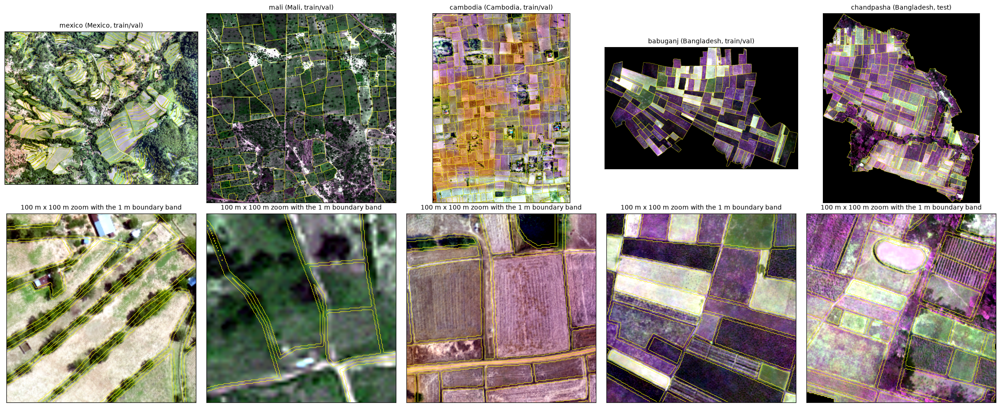

In [3]:
# Step 2. One 0.5 m grid per site, RGB only, normalised per site, and the boundary reference.
MALI_WINDOW = 1536.0      # Mali covers 5.6 km x 3.5 km at 2 m; one 1.5 km x 1.5 km window is used

def densest_window(fields, size, step=128.0):
    """Lower-left corner of the size x size window that holds the most digitised field centroids."""
    c = fields.centroid
    x0, y0, x1, y1 = fields.total_bounds
    best = max(((x, y) for x in np.arange(x0, x1 - size, step) for y in np.arange(y0, y1 - size, step)),
               key=lambda p: int(((c.x >= p[0]) & (c.x < p[0] + size) & (c.y >= p[1]) & (c.y < p[1] + size)).sum()))
    return best

def to_grid(site):
    """Resample the site's red, green and blue bands to a 0.5 m grid in the site's own UTM zone.
    Finer images are averaged down; Mali (2 m) is interpolated up. White (255) is no-data in the
    Bangladesh images (outside the drone flight); all other images are complete."""
    country, rgb, role = SITES[site]
    with rasterio.open(DATA / "Images" / f"{site}.tif") as r:
        b = r.bounds
        if site == "mali":
            x, y = densest_window(FIELDS[site].to_crs(r.crs), MALI_WINDOW)
            b = rasterio.coords.BoundingBox(x, y, x + MALI_WINDOW, y + MALI_WINDOW)
        T = from_origin(round(b.left, 1), round(b.top, 1), GSD, GSD)
        H, W = int((b.top - b.bottom) // GSD), int((b.right - b.left) // GSD)
        X = np.full((3, H, W), np.nan, "float32")
        for i, band in enumerate(rgb):
            reproject(rasterio.band(r, band), X[i], dst_transform=T, dst_crs=r.crs, dst_nodata=np.nan,
                      src_nodata=255 if country == "Bangladesh" else None,
                      resampling=Resampling.bilinear if r.res[0] > GSD else Resampling.average)
        crs = r.crs
    ok = np.isfinite(X).all(0)
    # Per-site 2-98 % stretch on the valid pixels. The five images come from different sensors and
    # dates (WorldView, drone, aerial), so a shared stretch would put them on different brightness
    # levels; the per-site stretch uses no labels and is applied in the same way to the test site.
    lo, hi = np.nanpercentile(X[:, ok], 2, axis=1), np.nanpercentile(X[:, ok], 98, axis=1)
    Xn = np.nan_to_num(np.clip((X - lo[:, None, None]) / (hi - lo)[:, None, None], 0, 1)).astype("float32")
    fields = FIELDS[site].to_crs(crs)
    boundary, labelled = ed.rasterize_boundaries(fields, transform=T, shape=(H, W), buffer=0.5, return_valid=True)
    valid = labelled & ok
    return {"X": Xn, "B": boundary.astype("int64"), "V": valid, "ok": ok, "T": T, "crs": crs, "fields": fields,
            "extent": (T.c, T.c + W * GSD, T.f - H * GSD, T.f)}

t0 = time.perf_counter()
G = {s: to_grid(s) for s in SITES}
grid_tbl = pd.DataFrame({s: {"grid (px)": f"{g['X'].shape[2]} x {g['X'].shape[1]}",
                             "labelled share": f"{g['V'].mean():.0%}",
                             "boundary share of labelled": f"{g['B'][g['V']].mean():.1%}",
                             "role": SITES[s][2]} for s, g in G.items()}).T
print(f"five sites resampled to {GSD} m in {time.perf_counter() - t0:.0f} s")
display(grid_tbl)

def rgb(g):
    return np.moveaxis(g["X"], 0, -1)

def busiest_window(g, n=200):
    """The n x n pixel window (on a 50 px raster) with the most labelled boundary pixels, for zooms."""
    bb = np.where(g["V"], g["B"], 0)
    h, w = bb.shape
    r0, c0 = max(((r, c) for r in range(0, h - n, 50) for c in range(0, w - n, 50)),
                 key=lambda p: bb[p[0]:p[0] + n, p[1]:p[1] + n].sum())
    return (slice(r0, r0 + n), slice(c0, c0 + n))

fig, ax = plt.subplots(2, 5, figsize=(22, 9))
for k, (s, g) in enumerate(G.items()):
    ax[0, k].imshow(rgb(g), extent=g["extent"]); g["fields"].boundary.plot(ax=ax[0, k], color="yellow", lw=0.3)
    ax[0, k].set_xlim(g["extent"][:2]); ax[0, k].set_ylim(g["extent"][2:])
    ax[0, k].set_title(f"{s} ({SITES[s][0]}, {SITES[s][2]})")
    z = busiest_window(g)
    ax[1, k].imshow(rgb(g)[z]); ax[1, k].contour(np.where(g["V"][z], g["B"][z], 0), levels=[0.5], colors="yellow", linewidths=0.6)
    ax[1, k].set_title("100 m x 100 m zoom with the 1 m boundary band")
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Labelled area and boundary share.**

- **Labelled share.** Cambodia is digitised wall to wall. In Mexico only the terraces are digitised (37 % of the grid); the forest between them is left out. The Mali window is 64 % labelled, and the two Bangladesh sites 57 to 58 % (the drone flight).
- **Boundary share.** Boundaries make up 15 % of the labelled pixels in the two Bangladesh sites and in Mexico, 10 % in Cambodia and only 4.6 % in Mali, whose fields are much larger.
- **The images (top row).** The two Bangladesh drone images look purple in this RGB display. They are stretched in the same way, so the training site and the test site look alike.

## Tiles, a spatial split and rotation augmentation

- **Tiles.** 192 x 192 pixels (96 m x 96 m), at least half labelled. To get enough tiles from the small Bangladesh site, tiles start every 96 px but must lie inside one 2 x 2-tile block.
- **Split.** Each training site is divided into 192 m blocks. About 20 % of each site's tiles (whole blocks) are used for validation. Large sites are capped at about 240 tiles so that they do not dominate (only Mali reaches the cap).
- **Augmentation.** Training tiles are rotated by 90°, 180° and 270°. Babuganj, the only Bangladesh training site and the smallest, also gets the four mirrored rotations.
- **Test.** Chandpasha is not tiled. Every method is applied to the whole site and scored on all its digitised pixels.


split,train,val,All
site,,,
babuganj,14,7,21
cambodia,81,27,108
mali,189,54,243
mexico,96,32,128
All,380,120,500


training set after augmentation: 1576 tiles (112 from Babuganj); validation 120 tiles


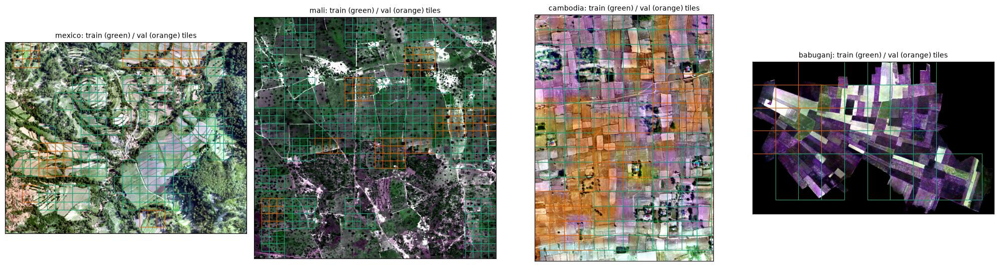

In [4]:
# Step 3. Tiles, a spatial split inside each training site, and rotation augmentation.

# 1. 192 x 192 tiles (96 m x 96 m). Each site is divided into 2 x 2-tile blocks (192 m x 192 m);
#    a whole block goes to training or to validation. Tiles start every 96 px but must lie inside
#    one block, so overlapping tiles never cross the train/validation line.
#    Chandpasha is not tiled: the test is the whole site (Step 4).
BLOCK, STRIDE, VAL_SHARE, CAP = 2 * TILE, TILE // 2, 0.2, 240
rng = np.random.default_rng(SEED)
T_IMG, T_LAB, T_VAL, T_SITE, T_SPLIT, T_ORIG = [], [], [], [], [], []
for s, g in G.items():
    if SITES[s][2] != "train/val":
        continue
    t = ed.tile_pairs(np.moveaxis(g["X"], 0, -1), np.where(g["V"], g["B"], 0), size=TILE, stride=STRIDE,
                      valid=g["V"], min_valid=0.5)
    inside = ((t["origins"] % BLOCK) <= BLOCK - TILE).all(1)
    o = t["origins"][inside]
    blk = [tuple(v) for v in o // BLOCK]
    blocks = sorted(set(blk)); rng.shuffle(blocks)
    # About 20 % of each site's tiles go to validation; large sites are capped at CAP tiles
    # (whole blocks are drawn until the cap is reached) so Mexico and Mali do not swamp the rest.
    keep, side, n_val, n_kept = [], {}, 0, 0
    n_target = min(len(o), CAP)
    for b in blocks:
        n = blk.count(b)
        if n_kept >= n_target:
            break
        side[b] = "val" if n_val < VAL_SHARE * n_target else "train"
        n_val += n * (side[b] == "val"); n_kept += n
    pick = np.array([b in side for b in blk])
    sel = np.flatnonzero(inside)[pick]
    T_IMG.append(t["images"][sel]); T_LAB.append(t["labels"][sel]); T_VAL.append(t["valid"][sel])
    T_ORIG.append(t["origins"][sel]); T_SITE += [s] * len(sel)
    T_SPLIT += [side[b] for b, k in zip(blk, pick) if k]
X_all, LAB, SCORED = np.concatenate(T_IMG), np.concatenate(T_LAB), np.concatenate(T_VAL)
ORIG, T_SITE, T_SPLIT = np.concatenate(T_ORIG), np.array(T_SITE), np.array(T_SPLIT)
Y_all = np.where(SCORED, LAB, -100)                      # -100 = not labelled (ignored in the loss)
idx = {sp: np.flatnonzero(T_SPLIT == sp) for sp in ("train", "val")}
tile_id = np.array([f"{s}_r{r}_c{c}" for s, (r, c) in zip(T_SITE, ORIG)])
ic.check_split_isolation(train=tile_id[idx["train"]], val=tile_id[idx["val"]])
display(pd.crosstab(pd.Series(T_SITE, name="site"), pd.Series(T_SPLIT, name="split"), margins=True))

# 2. The four training sites are rotated by 0, 90, 180 and 270 degrees (Babuganj, the smallest,
#    also gets the four mirrored rotations so Bangladesh is not under-represented).
tr = idx["train"]
bab = T_SITE[tr] == "babuganj"
Xa, Ya = ed.dihedral_augment(X_all[tr[~bab]], Y_all[tr[~bab]], rotations=(0, 1, 2, 3))
Xb, Yb = ed.dihedral_augment(X_all[tr[bab]], Y_all[tr[bab]], rotations=(0, 1, 2, 3), flips=True)
Xtr, Ytr = np.concatenate([Xa, Xb]), np.concatenate([Ya, Yb])
print(f"training set after augmentation: {len(Xtr)} tiles ({len(Xb)} from Babuganj); validation {len(idx['val'])} tiles")

# 3. Where the training and validation blocks are.
fig, ax = plt.subplots(1, 4, figsize=(20, 5.4))
colours = {"train": "#1b9e77", "val": "#d95f02"}
for a, s in zip(ax, [s for s in SITES if SITES[s][2] == "train/val"]):
    a.imshow(rgb(G[s])); a.set_xticks([]); a.set_yticks([])
    for (r, c), sp in zip(ORIG[T_SITE == s], T_SPLIT[T_SITE == s]):
        a.add_patch(plt.Rectangle((c, r), TILE, TILE, fill=False, ec=colours[sp], lw=0.8))
    a.set_title(f"{s}: train (green) / val (orange) tiles")
plt.tight_layout(); plt.show()

**Tile counts.** 500 tiles in total: 380 for training and 120 for validation, 243 from Mali, 128 from Mexico, 108 from Cambodia and 21 from Babuganj (14 training, 7 validation). Babuganj is small and only 57 % flown, so even with overlapping tiles it gives few. After augmentation there are 1,576 training tiles, 112 of them from Babuganj. `ic.check_split_isolation` confirms that no tile is in both splits.

## Evaluation protocol

For the boundary class, with TP, FP and FN counted over the scored pixels (paper Eqs. 1–3):

$$\text{Precision} = \frac{TP}{TP + FP}, \qquad \text{Recall} = \frac{TP}{TP + FN}, \qquad F_1 = 2\,\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision} + \text{Recall}}$$

The same is computed for the non-boundary (field) class, and AUC from the continuous score. Every method's score becomes a boundary map with **one** threshold: the one that maximises boundary F1 on the pooled validation tiles of the four training sites (`ed.select_threshold`). With that threshold, the validation tiles of each training site and the whole Chandpasha site are scored.


In [5]:
# Step 4. Evaluation protocol shared by every method.
TEST = "chandpasha"
TG = G[TEST]                                 # the independent test site, scored as one whole scene
TRUTH = LAB                                  # (N, 192, 192) 0/1 labels of the training-site tiles
TRAIN_SITES = [s for s in SITES if SITES[s][2] == "train/val"]

def cut(score2d, which):
    """Tiles of a full-site score map for the tile indices `which` (all from one site)."""
    return np.stack([score2d[r:r + TILE, c:c + TILE] for r, c in ORIG[which]])

RESULTS, CURVES, TEST_MAPS, VAL_SCORES = [], {}, {}, {}

def evaluate(name, val_scores, test_map, *, kind, threshold=None, tolerance=0, record=True):
    """Pick the threshold on the pooled validation tiles of the four training sites (maximum
    boundary F1), then score the validation tiles of each site and the whole Chandpasha site.
    val_scores: (n_val, 192, 192) boundary scores in the order of idx['val'];
    test_map: (H, W) boundary score of the test site."""
    v = idx["val"]
    if threshold is None:
        threshold, _ = ed.select_threshold(val_scores, TRUTH[v], valid=SCORED[v], tolerance=tolerance)
    rows = []
    for site in TRAIN_SITES + ["all four"]:
        k = np.ones(len(v), bool) if site == "all four" else T_SITE[v] == site
        m = ed.edge_metrics(val_scores[k], TRUTH[v][k], threshold=threshold, valid=SCORED[v][k], tolerance=tolerance)
        rows.append({"method": name, "kind": kind, "split": "validation", "site": site, "tolerance_px": tolerance, **m})
    m = ed.edge_metrics(test_map, TG["B"], threshold=threshold, valid=TG["V"], tolerance=tolerance)
    rows.append({"method": name, "kind": kind, "split": "test", "site": TEST, "tolerance_px": tolerance, **m})
    if record:
        RESULTS[:] = [r for r in RESULTS if not (r["method"] == name and r["tolerance_px"] == tolerance)] + rows
        VAL_SCORES[name], TEST_MAPS[name] = val_scores, test_map
        if tolerance == 0:
            from sklearn.metrics import roc_curve
            ok = TG["V"] & np.isfinite(test_map)
            pick = np.random.default_rng(0).choice(ok.sum(), min(300_000, ok.sum()), replace=False)
            fpr, tpr, _ = roc_curve(TG["B"][ok][pick], test_map[ok][pick])
            CURVES[name] = (fpr, tpr, m["auc"])
    return threshold

def table(split="test", tolerance=0, site=None, cols=("boundary_precision", "boundary_recall", "boundary_f1",
                                                      "field_precision", "field_recall", "field_f1", "auc", "threshold")):
    df = pd.DataFrame(RESULTS)
    df = df[(df.split == split) & (df.tolerance_px == tolerance)]
    if site is not None:
        df = df[df.site == site]
    return df.set_index(["kind", "method"] + ([] if site else ["site"]))[list(cols)].round(3)

v = idx["val"]
print(f"scored pixels: training tiles {SCORED[idx['train']].sum():,}, validation tiles {SCORED[v].sum():,}, "
      f"Chandpasha {TG['V'].sum():,}")
print(f"boundary share: validation {TRUTH[v][SCORED[v]].mean():.1%}, Chandpasha {TG['B'][TG['V']].mean():.1%}")

scored pixels: training tiles 12,224,559, validation tiles 3,773,737, Chandpasha 608,093
boundary share: validation 9.0%, Chandpasha 15.2%


Boundaries are a larger share of the test site than of the validation tiles, because the Chandpasha plots are smaller (median 317 m²) than the Mexico, Mali and Cambodia fields. Boundary F1 depends on this share, so validation and test F1 are not directly comparable between sites. They are comparable between methods on the same site.

## Traditional edge detectors

Roberts, Sobel, Prewitt, Laplacian of Gaussian and Canny measure how fast the brightness changes (see 09_10_03 for the formulas). `ed.classical_edges` runs each detector on the R, G and B bands and keeps the strongest response. The threshold is the same validation-based choice as for every other method, except Canny, which returns binary edges.


5 detectors on five sites in 20 s


,,boundary_precision,boundary_recall,boundary_f1,field_f1,auc,threshold
method,site,,,,,,
Roberts,chandpasha,0.239,0.456,0.314,0.805,0.638,0.3
Sobel,chandpasha,0.344,0.546,0.422,0.858,0.749,0.3
Prewitt,chandpasha,0.346,0.547,0.424,0.859,0.750,0.3
Laplacian of Gaussian,chandpasha,0.233,0.421,0.300,0.809,0.628,0.3
Canny,chandpasha,0.265,0.359,0.305,0.848,0.591,0.5


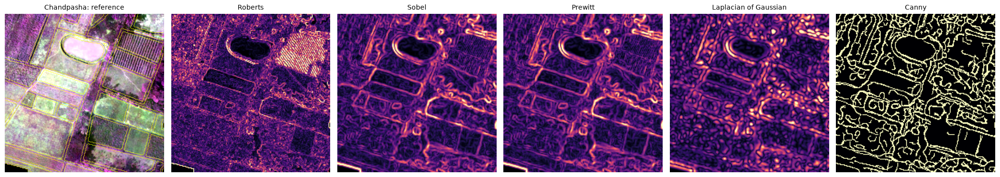

In [6]:
# Step 5. Traditional edge detectors on the RGB image of every site.
CLASSICAL = {"Roberts": ("roberts", 0.0), "Sobel": ("sobel", 1.0), "Prewitt": ("prewitt", 1.0),
             "Laplacian of Gaussian": ("log", 2.0), "Canny": ("canny", 2.0)}
edge_maps = {}
t0 = time.perf_counter()
for name, (method, sigma) in CLASSICAL.items():
    maps = {s: ed.classical_edges(rgb(G[s]), method, sigma=sigma) for s in SITES}
    edge_maps[name] = maps
    val_s = np.zeros((len(v), TILE, TILE), "float32")
    for s in TRAIN_SITES:
        k = np.flatnonzero(T_SITE[v] == s)
        val_s[k] = cut(maps[s], v[k])
    evaluate(name, val_s, maps[TEST], kind="1 classical", threshold=0.5 if method == "canny" else None)
print(f"{len(CLASSICAL)} detectors on five sites in {time.perf_counter() - t0:.0f} s")
display(table().loc["1 classical"].drop(columns=["field_precision", "field_recall"]))

zoom = busiest_window(TG)
fig, ax = plt.subplots(1, 6, figsize=(21, 3.9))
ax[0].imshow(rgb(TG)[zoom]); ax[0].contour(TG["B"][zoom] * TG["V"][zoom], levels=[0.5], colors="yellow", linewidths=0.5)
ax[0].set_title("Chandpasha: reference")
for a, name in zip(ax[1:], CLASSICAL):
    a.imshow(edge_maps[name][TEST][zoom], cmap="magma", vmin=0, vmax=1); a.set_title(name)
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

**Traditional detectors on Chandpasha.**

| Detector | Boundary F1 | AUC |
|---|---|---|
| Prewitt | 0.424 | 0.75 |
| Sobel | 0.422 | 0.75 |
| Roberts | 0.31 | 0.64 |
| Canny | 0.31 | 0.59 |
| Laplacian of Gaussian | 0.30 | 0.63 |

Prewitt and Sobel are best, as in 09_10_03. The edge maps show why every detector stays low: the bunds give strong responses, but so do the dark rows of the striped fields, the tree canopy and the pond shore. A threshold cannot separate these from field boundaries.

## Random forest on texture features

As in the paper: 600 trees, maximum depth 30. The per-pixel features are:

- R, G and B;
- the 3 x 3 local standard deviation and the Sobel gradient of each band;
- LBP uniformity and entropy, and GLCM contrast, correlation, entropy and homogeneity of the grey image in 7 x 7 windows at 1 m.

The forest is trained on 10,000 boundary and 10,000 non-boundary pixels from the training tiles of each site (80,000 in total), so each country has the same weight.


texture layers for five sites in 251 s


15 features, 80,000 training pixels, fitted in 8 s


,boundary_precision,boundary_recall,boundary_f1,field_f1,auc,threshold
method,,,,,,
Random forest,0.315,0.501,0.387,0.849,0.74,0.65


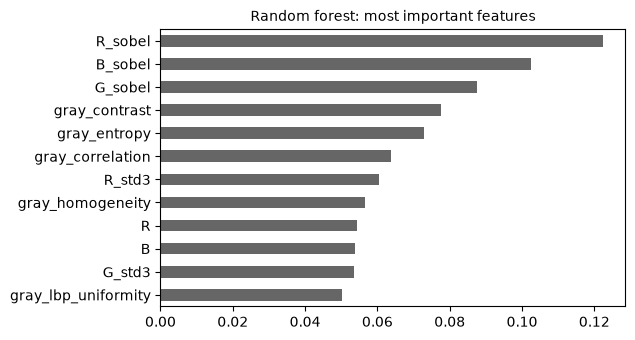

In [7]:
# Step 6. Random forest on spectral, gradient and texture features (the paper's baseline).
from scipy import ndimage as ndi
from skimage.filters import sobel
from sklearn.ensemble import RandomForestClassifier

# 1. Texture of the grey image (mean of R, G, B): local binary patterns and GLCM contrast,
#    correlation, entropy and homogeneity in 7 x 7 windows. It is computed on a 1 m version of
#    each site (2 x 2 mean) and interpolated back to 0.5 m: the paper computed texture at the
#    WorldView pixel size (1.6 m), and 1 m keeps the run to a few minutes for all five sites.
def site_texture(g):
    gray = g["X"].mean(0)
    h, w = gray.shape
    g1 = gray[: h // 2 * 2, : w // 2 * 2].reshape(h // 2, 2, w // 2, 2).mean((1, 3))
    lbp = texture.lbp_texture(g1, radius=1, n_points=8, size=7, step=1)
    glcm = texture.glcm_texture(g1, size=7, step=2, levels=32, props=("contrast", "correlation", "entropy", "homogeneity"))
    up = lambda a: np.pad(ndi.zoom(np.nan_to_num(np.asarray(a, "float32")), 2, order=1),
                          ((0, h - g1.shape[0] * 2), (0, w - g1.shape[1] * 2)), mode="edge")
    return {f"gray_{k}": up(v) for k, v in {**lbp, **glcm}.items()}

def rf_features(site):
    """Per-pixel features on the 0.5 m grid: band values, 3 x 3 local std, Sobel gradient, texture."""
    g, F = G[site], {}
    for b, nm in enumerate("RGB"):
        x = g["X"][b]
        F[nm] = x
        F[f"{nm}_std3"] = np.sqrt(np.maximum(ndi.uniform_filter(x ** 2, 3) - ndi.uniform_filter(x, 3) ** 2, 0))
        F[f"{nm}_sobel"] = sobel(ndi.gaussian_filter(x, 1.0))
    F.update(TEX[site])
    return F

t0 = time.perf_counter()
TEX = {s: site_texture(G[s]) for s in SITES}
print(f"texture layers for five sites in {time.perf_counter() - t0:.0f} s")
FEAT = {s: rf_features(s) for s in SITES}
NAMES = list(FEAT[TEST])

def stack_tiles(which):
    """(n, 192, 192, f) feature tiles for tile indices `which` (any mix of sites)."""
    out = np.empty((len(which), TILE, TILE, len(NAMES)), "float32")
    for s in set(T_SITE[which]):
        k = np.flatnonzero(T_SITE[which] == s)
        out[k] = np.stack([cut(FEAT[s][n], which[k]) for n in NAMES], -1)
    return out

# 2. A balanced sample of training-tile pixels, the same number from each site; 600 trees of
#    depth <= 30 as in the paper.
rng = np.random.default_rng(SEED)
Xs, ys = [], []
for s in TRAIN_SITES:
    w = idx["train"][T_SITE[idx["train"]] == s]
    Ft, yt, okt = stack_tiles(w), TRUTH[w], SCORED[w]
    for cls in (0, 1):
        p = np.flatnonzero(okt.ravel() & (yt.ravel() == cls))
        p = rng.choice(p, min(10_000, len(p)), replace=False)
        Xs.append(Ft.reshape(-1, len(NAMES))[p]); ys.append(np.full(len(p), cls))
t0 = time.perf_counter()
rf = RandomForestClassifier(n_estimators=600, max_depth=30, n_jobs=-1, random_state=SEED)
rf.fit(np.concatenate(Xs), np.concatenate(ys))
RF_FIT_S = time.perf_counter() - t0
Fv = stack_tiles(v)
rf_val = rf.predict_proba(Fv.reshape(-1, len(NAMES)))[:, 1].reshape(Fv.shape[:3]).astype("float32")
Ftest = np.stack([FEAT[TEST][n] for n in NAMES], -1)
rf_test = rf.predict_proba(Ftest.reshape(-1, len(NAMES)))[:, 1].reshape(Ftest.shape[:2]).astype("float32")
evaluate("Random forest", rf_val, rf_test, kind="2 random forest")
print(f"{len(NAMES)} features, {sum(map(len, ys)):,} training pixels, fitted in {RF_FIT_S:.0f} s")
display(table(site=TEST).loc["2 random forest"].drop(columns=["field_precision", "field_recall"]))
imp = pd.Series(rf.feature_importances_, NAMES).sort_values()
imp.tail(12).plot.barh(figsize=(6, 3.6), color="0.4", title="Random forest: most important features"); plt.show()

**Random forest on Chandpasha.** Boundary F1 is 0.39 and AUC 0.74, slightly below Sobel and Prewitt. Its threshold (0.65) was chosen on the pooled validation tiles.

**Features.** The three Sobel gradients are the most important, followed by GLCM contrast, entropy and correlation. The forest mostly learns a better-weighted gradient. Without context beyond a 7 x 7 window, it cannot tell a bund from other strong edges.

## The six networks

The six networks of the paper, built by `ed.build_edge_model` with three input channels:

| Network | Idea |
|---|---|
| **U-Net** | Encoder–decoder with skip connections that concatenate encoder features at each scale. |
| **SegNet** | VGG16 encoder; the decoder upsamples with the encoder's max-pooling indices; no skip connections. |
| **FC-DenseNet56/67/103** | Dense blocks in which each layer sees the feature maps of all earlier layers in the block. |
| **FCN-DKConv6** | Six 5 x 5 dilated convolutions, no pooling; 117 k parameters. |

All use pixel-wise cross-entropy, Adam with L2 weight decay 1e-4, a cosine learning-rate schedule and batch size 4. They are trained for 30 epochs, and the epoch with the best validation mean IoU is kept. Unlabelled pixels carry the label -100 and are ignored by the loss. SegNet, as in 09_10_03, uses class-weighted cross-entropy.


In [8]:
# Step 7a. The six networks of the paper, built with geolattice.rsense.edge_detectors (3 input channels).
NETS = {                                   # name -> (edge_detectors model name, keyword arguments)
    "U-Net": ("unet_basic", {"base": 64, "depth": 4, "dropout": 0.5}),
    "SegNet": ("SegNet", {"dropout_p": 0.5}),
    "FC-DenseNet56": ("FC-DenseNet56", {}),
    "FC-DenseNet67": ("FC-DenseNet67", {}),
    "FC-DenseNet103": ("FC-DenseNet103", {}),
    "FCN-DKConv6": ("FCN-DKConv6", {}),
}
display(pd.DataFrame([{"network": n, "GeoLattice model": a,
                       "parameters": f"{ic.count_parameters(ed.build_edge_model(a, in_channels=3, device='cpu', **kw)):,}"}
                      for n, (a, kw) in NETS.items()]).set_index("network"))

# 1,576 augmented training tiles is nine times the 09_10_03 training set, so 30 epochs give more
# weight updates than the 60 epochs used there.
TRAIN = {"epochs": 30, "batch": 4, "lr": 1e-3, "weight_decay": 1e-4}
NET_DIR = OUT / "models"
NET_DIR.mkdir(exist_ok=True)

# SegNet has no skip connections and, as in 09_10_03, needs class-weighted cross-entropy
# (boundary weight = non-boundary / boundary pixels of the training tiles) to find boundaries at all.
SHARE = float((Ytr == 1).sum() / (Ytr >= 0).sum())
CLASS_W = torch.tensor([1.0, (1 - SHARE) / SHARE], dtype=torch.float32)
SPECIAL = {"SegNet": {"loss": torch.nn.CrossEntropyLoss(weight=CLASS_W, ignore_index=-100)}}
print(f"boundary share of training pixels {SHARE:.3f}; SegNet boundary weight {CLASS_W[1]:.2f}")

def train_net(name, *, data=None, val=None, epochs=None, lr=None, tag=""):
    """Train one network (or load it if trained before) and return (model, history, seconds).
    Cross-entropy, Adam with L2 weight decay, cosine schedule; the weights of the epoch with the
    best validation mean IoU (pooled validation tiles of the four sites, or the tiles `val`) are kept."""
    arch, kw = NETS[name]
    sp = SPECIAL.get(name, {})
    Xt, Yt = (Xtr, Ytr) if data is None else data
    epochs, lr = epochs or sp.get("epochs", TRAIN["epochs"]), lr or TRAIN["lr"]
    pt, js = NET_DIR / f"{name}{tag}.pt", NET_DIR / f"{name}{tag}.json"
    model = ed.build_edge_model(arch, in_channels=3, device=DEVICE, **kw)
    if pt.exists():
        model.load_state_dict(torch.load(pt, map_location=DEVICE))
        meta = json.loads(js.read_text())
        return model.eval(), meta["history"], meta["seconds"]
    ic.set_seed(SEED)
    train_dl = ic.as_loader(ic.ChipDataset(Xt, Yt), TRAIN["batch"], shuffle=True, seed=SEED)
    vv = v if val is None else val
    val_dl = ic.as_loader(ic.ChipDataset(X_all[vv], Y_all[vv]), 8, shuffle=False)
    t0 = time.perf_counter()
    hist = ic.train_model(model, train_dl, val_dl, task="segmentation", epochs=epochs, loss=sp.get("loss", "ce"),
                          optimizer="adam", lr=lr, weight_decay=TRAIN["weight_decay"], scheduler="cosine",
                          num_classes=2, ignore_index=-100, monitor="val_score", device=DEVICE,
                          seed=SEED, verbose=False)
    seconds = time.perf_counter() - t0
    torch.save(model.state_dict(), pt)
    js.write_text(json.dumps({"history": hist, "seconds": seconds, "epochs": epochs, "lr": lr}))
    return model.eval(), hist, seconds

def net_val(model, which=None):
    """Boundary probability (softmax of class 1) of the validation tiles (or of tiles `which`)."""
    which = v if which is None else which
    return ic.predict_proba_batches(model, X_all[which], batch_size=8, device=DEVICE)[:, 1].astype("float32")

def net_test(model):
    """Boundary probability of the whole Chandpasha site: overlapping 192 x 192 windows blended
    with a Hann weight (the image is already in [0, 1])."""
    return ed.predict_boundary_probability(rgb(TG), model, tile_size=TILE, overlap=64, batch_size=8,
                                           device=DEVICE, image_range=(0, 1)).astype("float32")

,GeoLattice model,parameters
network,,
U-Net,unet_basic,"31,037,698"
SegNet,SegNet,"29,472,194"
FC-DenseNet56,FC-DenseNet56,"1,375,058"
FC-DenseNet67,FC-DenseNet67,"3,460,642"
FC-DenseNet103,FC-DenseNet103,"9,319,778"
FCN-DKConv6,FCN-DKConv6,"116,818"


boundary share of training pixels 0.082; SegNet boundary weight 11.26


### Learning-rate sensitivity

FC-DenseNet56, five epochs at each of three learning rates, scored on the pooled validation tiles:


In [9]:
# Step 7b. Learning-rate sensitivity (cf. paper Table 6): FC-DenseNet56, 5 epochs per rate.
sweep = []
for lr in (1e-2, 1e-3, 1e-4):
    model, hist, sec = train_net("FC-DenseNet56", epochs=5, lr=lr, tag=f"_lr{lr:.0e}")
    s_val = net_val(model)
    th, _ = ed.select_threshold(s_val, TRUTH[v], valid=SCORED[v])
    m = ed.edge_metrics(s_val, TRUTH[v], threshold=th, valid=SCORED[v])
    sweep.append({"learning rate": lr, "best val mIoU": max(hist["val_score"]), "val boundary F1": m["boundary_f1"],
                  "val AUC": m["auc"], "minutes": sec / 60})
    del model; torch.cuda.empty_cache()
display(pd.DataFrame(sweep).set_index("learning rate").round(3))

,best val mIoU,val boundary F1,val AUC,minutes
learning rate,,,,
0.0100,0.543,0.426,0.836,2.797
0.0010,0.654,0.588,0.921,2.917
0.0001,0.584,0.529,0.886,2.924


**Learning rate.** 1e-3 is clearly best after five epochs: validation mean IoU 0.65 and boundary F1 0.59, against 0.58 and 0.53 for 1e-4 and 0.54 and 0.43 for 1e-2. All six networks use 1e-3, as in 09_10_03.

### Training on the four sites


In [10]:
# Step 7c. Train the six networks on the four training sites and score them (about 1.7 h on one
# GPU; re-runs load the saved weights from outputs/edge_detection_global/models).
MODELS, HIST, SECONDS = {}, {}, {}
for name in NETS:
    model, hist, sec = train_net(name)
    MODELS[name], HIST[name], SECONDS[name] = model, hist, sec
    th = evaluate(name, net_val(model), net_test(model), kind="3 network")
    r = [r for r in RESULTS if r["method"] == name and r["split"] == "test"][-1]
    print(f"{name:15s} {sec / 60:5.1f} min | threshold {th:.2f} | Chandpasha boundary F1 {r['boundary_f1']:.3f}, AUC {r['auc']:.3f}")

U-Net            12.0 min | threshold 0.30 | Chandpasha boundary F1 0.541, AUC 0.841


SegNet           11.8 min | threshold 0.65 | Chandpasha boundary F1 0.305, AUC 0.651


FC-DenseNet56    17.4 min | threshold 0.35 | Chandpasha boundary F1 0.500, AUC 0.826


FC-DenseNet67    32.1 min | threshold 0.35 | Chandpasha boundary F1 0.601, AUC 0.878


FC-DenseNet103   29.5 min | threshold 0.35 | Chandpasha boundary F1 0.600, AUC 0.882


FCN-DKConv6       4.7 min | threshold 0.30 | Chandpasha boundary F1 0.523, AUC 0.840


**Training.** Every network except SegNet ends within 0.04 of the others on the pooled validation tiles (boundary F1 0.59 to 0.63). SegNet reaches 0.43. The next step shows how much of this carries over to the unseen site.

## Results

### The independent test site and the validation tiles of each training site


In [11]:
# Step 8a. Results: the independent test site, and validation in each training site.
ORDER = ["Roberts", "Sobel", "Prewitt", "Laplacian of Gaussian", "Canny", "Random forest",
         "FCN-DKConv6", "U-Net", "SegNet", "FC-DenseNet56", "FC-DenseNet67", "FC-DenseNet103"]
df = pd.DataFrame(RESULTS)
df = df[df.tolerance_px == 0]

# 1. Chandpasha (Bangladesh, never seen in training), in the layout of the paper's Tables 7-8.
t = df[df.split == "test"].set_index("method").loc[ORDER]
test_tbl = t[["boundary_precision", "boundary_recall", "boundary_f1", "field_precision", "field_recall", "field_f1", "auc"]]
test_tbl.columns = pd.MultiIndex.from_tuples([("Boundary", "Precision"), ("Boundary", "Recall"), ("Boundary", "F1"),
                                              ("Field", "Precision"), ("Field", "Recall"), ("Field", "F1"), ("", "AUC")])
print("Independent test site Chandpasha (threshold chosen on the validation tiles of the four training sites)")
display(test_tbl.round(3))

# 2. Boundary F1 on the validation tiles of each training site, next to the test site.
val_f1 = df.pivot_table(index="method", columns="site", values="boundary_f1").loc[ORDER]
val_f1 = val_f1[TRAIN_SITES + ["all four", TEST]]
val_f1.columns = [f"{c} (val)" if c != TEST else f"{c} (test)" for c in val_f1.columns]
print("Boundary F1 by site")
display(val_f1.round(3))

Independent test site Chandpasha (threshold chosen on the validation tiles of the four training sites)


Boundary                   Field                     
                      Precision Recall     F1 Precision Recall     F1    AUC
method                                                                      
Roberts                   0.239  0.456  0.314     0.883  0.739  0.805  0.638
Sobel                     0.344  0.546  0.422     0.909  0.813  0.858  0.749
Prewitt                   0.346  0.547  0.424     0.909  0.814  0.859  0.750
Laplacian of Gaussian     0.233  0.421  0.300     0.878  0.751  0.809  0.628
Canny                     0.265  0.359  0.305     0.877  0.822  0.848  0.591
Random forest             0.315  0.501  0.387     0.900  0.804  0.849  0.740
FCN-DKConv6               0.439  0.646  0.523     0.930  0.852  0.890  0.840
U-Net                     0.621  0.480  0.541     0.910  0.947  0.928  0.841
SegNet                    0.243  0.410  0.305     0.879  0.771  0.821  0.651
FC-DenseNet56             0.406  0.651  0.500     0.930  0.829  0.876  0.826
FC-DenseNet67             0.547  0.667  0.601     0.938  0.901  0.919  0.878
FC-DenseNet103            0.548  0.663  0.600     0.937  0.902  0.919  0.882

Boundary F1 by site


,mexico (val),mali (val),cambodia (val),babuganj (val),all four (val),chandpasha (test)
method,,,,,,
Roberts,0.365,0.215,0.356,0.392,0.327,0.314
Sobel,0.503,0.226,0.368,0.589,0.389,0.422
Prewitt,0.504,0.226,0.368,0.590,0.390,0.424
Laplacian of Gaussian,0.367,0.203,0.364,0.358,0.320,0.300
Canny,0.327,0.099,0.179,0.399,0.213,0.305
Random forest,0.539,0.229,0.462,0.603,0.423,0.387
FCN-DKConv6,0.642,0.288,0.683,0.655,0.591,0.523
U-Net,0.648,0.295,0.699,0.693,0.608,0.541
SegNet,0.509,0.268,0.422,0.495,0.428,0.305


**Chandpasha, never seen in training (first table).**

- **FC-DenseNet67 and FC-DenseNet103** are best, with boundary F1 0.60 and AUC 0.88.
- **U-Net** (0.54), **FCN-DKConv6** (0.52) and **FC-DenseNet56** (0.50) follow. U-Net is the most conservative: highest precision (0.62) and lowest recall (0.48) of the networks.
- **SegNet** (0.31, AUC 0.65) is again the weakest network. It is below Sobel and Prewitt (0.42) and the random forest (0.39).
- The field (non-boundary) class is easy for every method: F1 0.80 to 0.93.

**Validation by site (second table).**

- **Mali is the hardest site** for every method: boundary F1 at most 0.32. Its 2 m image was interpolated to 0.5 m, so a 1 m boundary band is a quarter of an image pixel wide, and many Mali boundaries are rows of trees or unploughed strips, not bunds.
- **Cambodia, Mexico and Babuganj** reach 0.63 to 0.73 for the networks (SegNet excepted).
- On Chandpasha the best networks lose only about 0.03 against their pooled validation score (0.63 to 0.60). The smaller networks lose 0.07 to 0.09. Step 10 looks at this gap.

### Learning curves and training time (paper Figs. 8 and 9)


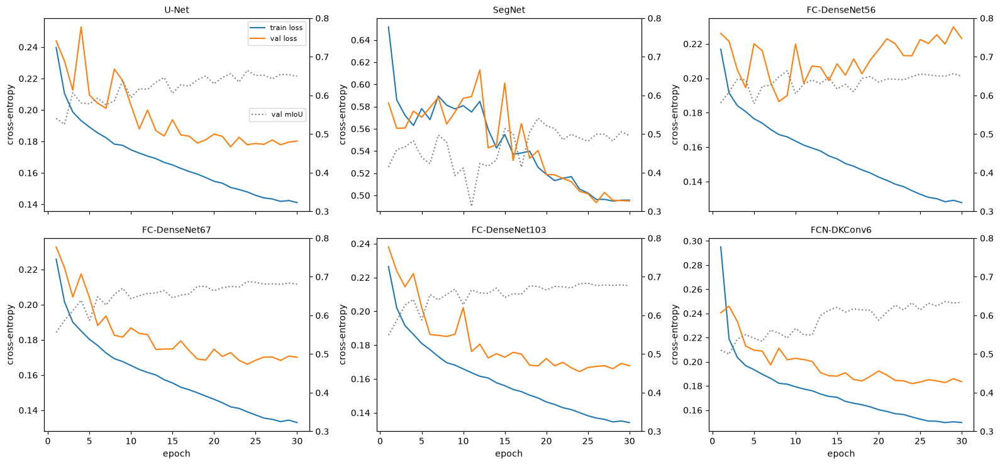

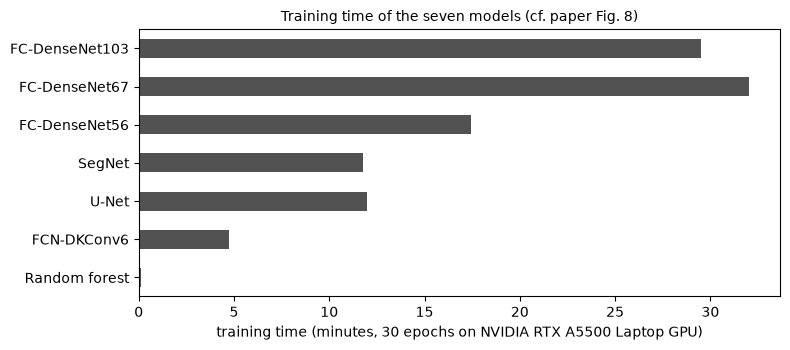

In [12]:
# Step 8b. Learning curves (cf. paper Fig. 9) and training time (cf. Fig. 8).
nets = list(NETS)
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True)
for a, name in zip(ax.ravel(), nets):
    h = HIST[name]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    a.plot(ep, h["train_loss"], label="train loss"); a.plot(ep, h["val_loss"], label="val loss")
    a2 = a.twinx(); a2.plot(ep, h["val_score"], color="0.5", ls=":", label="val mIoU"); a2.set_ylim(0.3, 0.8)
    a.set_title(name); a.set_ylabel("cross-entropy")
    if name == nets[0]:
        a.legend(loc="upper right", fontsize=8); a2.legend(loc="center right", fontsize=8)
for a in ax[-1]:
    a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

times = pd.Series({"Random forest": RF_FIT_S / 60, **{n: SECONDS[n] / 60 for n in nets}}).loc[ORDER[5:]]
ax = times.plot.barh(figsize=(8, 3.6), color="#525252")
ax.set_xlabel(f"training time (minutes, {TRAIN['epochs']} epochs on {torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU'})")
ax.set_title("Training time of the seven models (cf. paper Fig. 8)"); plt.tight_layout(); plt.show()

**Learning curves.**

- **U-Net, FC-DenseNet67/103 and FCN-DKConv6.** Validation loss falls for most of the 30 epochs, and validation mean IoU levels off at 0.63 to 0.69. With nine times more training tiles than in 09_10_03, these networks no longer over-fit within the budget.
- **FC-DenseNet56.** Validation loss starts to rise after about epoch 10 while mean IoU stays flat, a mild over-fit. The kept weights are those of the best validation epoch.
- **SegNet.** Its curves are noisy, and validation mean IoU stays near 0.5.

**Training time (30 epochs, one RTX A5500).** FCN-DKConv6 takes 4.7 min, SegNet 11.8, U-Net 12.0, FC-DenseNet56 17.4, FC-DenseNet103 29.5 and FC-DenseNet67 32.1. The random forest fits in 8 s, after about 4 min of texture features. As in the paper and in 09_10_03, the dense networks are slow for their size.

### ROC curves on the test site (paper Fig. 10)


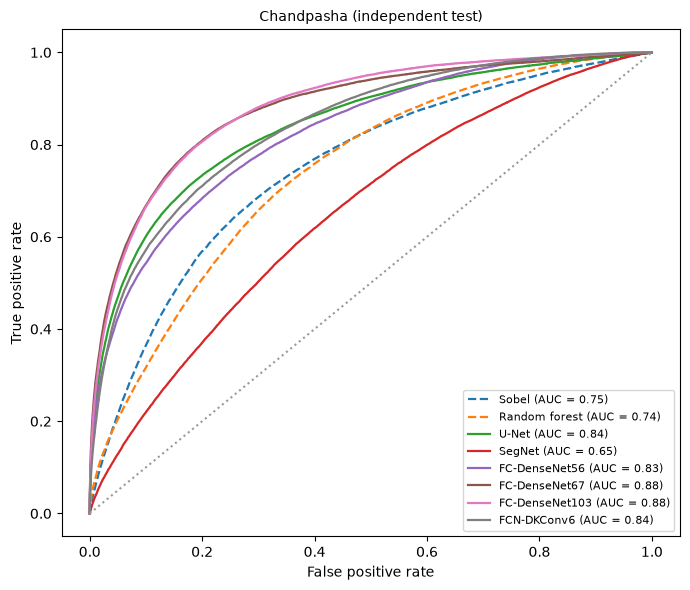

In [13]:
# Step 8c. ROC curves on the test site (cf. paper Fig. 10).
fig, ax = plt.subplots(figsize=(7, 6))
for name in ["Sobel", "Random forest"] + nets:
    fpr, tpr, auc = CURVES[name]
    ax.plot(fpr, tpr, lw=1.6, ls="--" if name in ("Sobel", "Random forest") else "-", label=f"{name} (AUC = {auc:.2f})")
ax.plot([0, 1], [0, 1], color="0.6", ls=":")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("Chandpasha (independent test)")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

The ROC curves of FC-DenseNet67 and FC-DenseNet103 (AUC 0.88) lie above the other networks over the whole range. U-Net, FCN-DKConv6 and FC-DenseNet56 follow at 0.83 to 0.84. Sobel (0.75) and the random forest (0.74) are close together, and SegNet (0.65) is closer to them than to the other networks.

### Predicted boundaries (paper Fig. 11)


best network on the pooled validation tiles: FC-DenseNet67


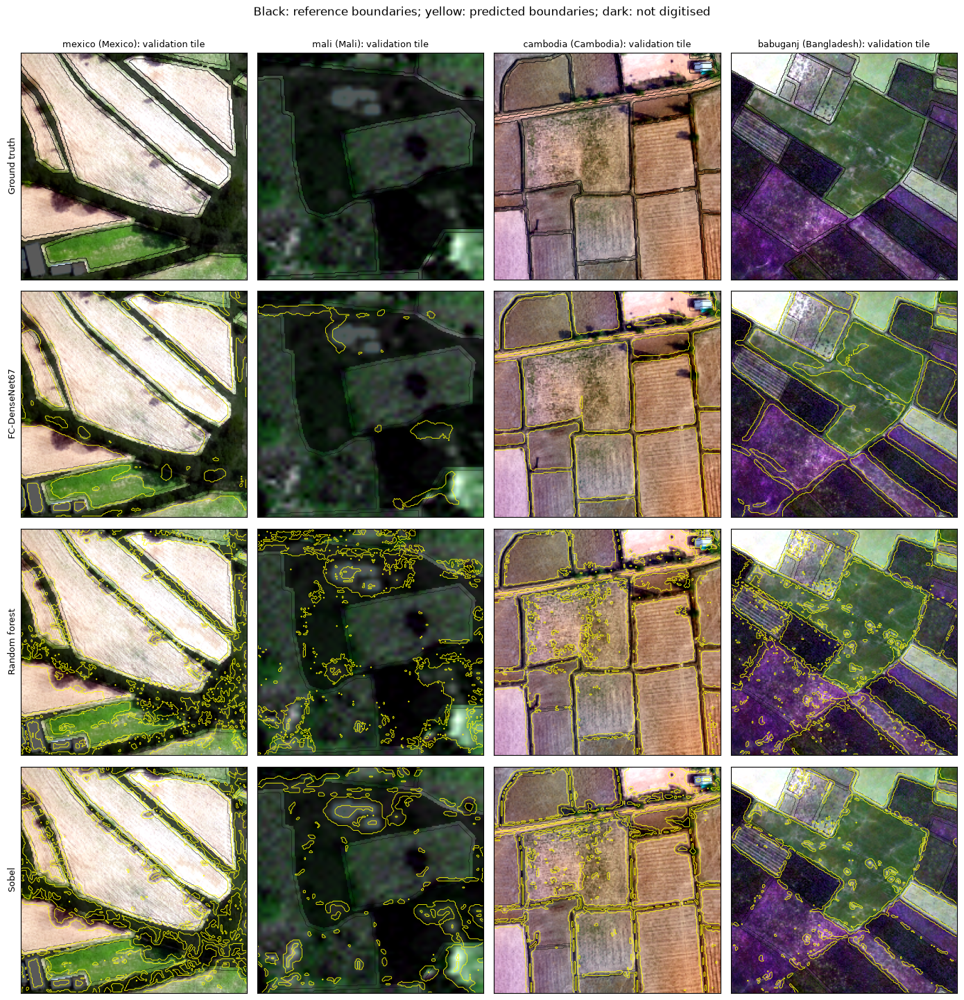

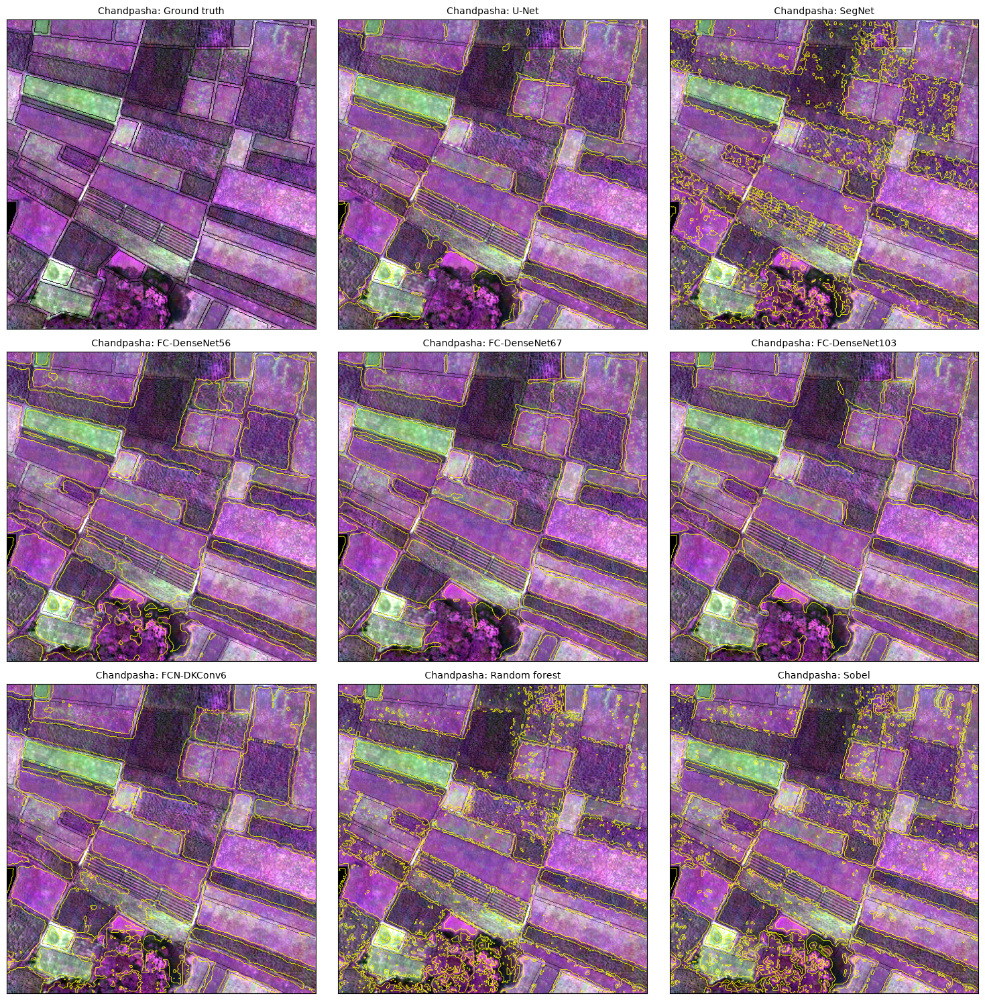

In [14]:
# Step 8d. Predicted boundaries: one validation tile per training site, and the test site (cf. paper Fig. 11).
thr = df[df.split == "test"].set_index("method")["threshold"]
BEST = df[(df.split == "validation") & (df.site == "all four") & (df.kind == "3 network")].sort_values("boundary_f1").method.iloc[-1]
print(f"best network on the pooled validation tiles: {BEST}")

rows = ["Ground truth", BEST, "Random forest", "Sobel"]
fig, ax = plt.subplots(len(rows), 4, figsize=(14, 3.6 * len(rows)))
for j, s in enumerate(TRAIN_SITES):
    k = np.flatnonzero(T_SITE[v] == s)
    k = k[np.argmax(TRUTH[v][k].sum((1, 2)))]                      # the validation tile with most boundary pixels
    img, ok, tru = np.moveaxis(X_all[v][k], 0, -1), SCORED[v][k], TRUTH[v][k]
    for i, name in enumerate(rows):
        a = ax[i, j]
        a.imshow(np.where(ok[..., None], img, img * 0.35))
        a.contour(tru * ok, levels=[0.5], colors="black", linewidths=0.6 if i == 0 else 0.3)
        if i:
            a.contour((VAL_SCORES[name][k] >= thr[name]).astype(float), levels=[0.5], colors="yellow", linewidths=0.6)
        a.set_xticks([]); a.set_yticks([])
        if i == 0:
            a.set_title(f"{s} ({SITES[s][0]}): validation tile", fontsize=9)
        if j == 0:
            a.set_ylabel(name, fontsize=9)
fig.suptitle("Black: reference boundaries; yellow: predicted boundaries; dark: not digitised", y=1.0)
plt.tight_layout(); plt.show()

# The test site: a 150 m x 150 m window, every network.
zoom = busiest_window(TG, 300)
show = ["Ground truth"] + nets + ["Random forest", "Sobel"]
fig, ax = plt.subplots(3, 3, figsize=(15, 15))
img, ok, tru = rgb(TG)[zoom], TG["V"][zoom], TG["B"][zoom]
for a, name in zip(ax.ravel(), show):
    a.imshow(np.where(ok[..., None], img, img * 0.35))
    a.contour(tru * ok, levels=[0.5], colors="black", linewidths=0.6 if name == "Ground truth" else 0.3)
    if name != "Ground truth":
        a.contour((TEST_MAPS[name][zoom] >= thr[name]).astype(float), levels=[0.5], colors="yellow", linewidths=0.6)
    a.set_title(f"Chandpasha: {name}"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Validation tiles (first figure).**

- In **Mexico, Cambodia and Babuganj**, FC-DenseNet67 draws closed, thin lines along the terrace edges, paddy bunds and plot borders.
- In **Mali** it draws almost nothing. Many of the digitised boundaries there have no visible edge at 2 m.
- **The random forest and Sobel** find the same strong edges, but they also fire on texture inside fields (tree crowns, furrows, the striped fields of Babuganj).

**Chandpasha (second figure).** The pattern is the same on the unseen site:

- the FC-DenseNets and U-Net outline nearly every plot with continuous lines;
- FCN-DKConv6 and FC-DenseNet56 add some short spurious lines inside the striped fields;
- SegNet, the random forest and Sobel produce speckle inside the dark, densely vegetated plots.

### How strict is pixel-exact scoring?


In [15]:
# Step 8e. How strict is pixel-exact scoring? Test F1 with a 0.5 m and 1 m positional tolerance.
rows = []
for name in ["Sobel", "Random forest"] + nets:
    for tol in (0, 1, 2):
        m = ed.edge_metrics(TEST_MAPS[name], TG["B"], threshold=thr[name], valid=TG["V"], tolerance=tol)
        rows.append({"method": name, "tolerance": f"{tol * GSD:g} m", "boundary F1": m["boundary_f1"]})
tol_tbl = pd.DataFrame(rows).pivot(index="method", columns="tolerance", values="boundary F1").loc[["Sobel", "Random forest"] + nets]
display(tol_tbl.round(3))

tolerance,0 m,0.5 m,1 m
method,,,
Sobel,0.422,0.605,0.690
Random forest,0.387,0.559,0.644
U-Net,0.541,0.698,0.758
SegNet,0.305,0.454,0.550
FC-DenseNet56,0.500,0.661,0.736
FC-DenseNet67,0.601,0.758,0.813
FC-DenseNet103,0.600,0.758,0.813
FCN-DKConv6,0.523,0.698,0.775


**Effect of positional tolerance on Chandpasha.**

- **0.5 m (one pixel).** Boundary F1 rises by 0.15 to 0.18 for every method.
- **1 m.** It rises by 0.21 to 0.27. FC-DenseNet67 and FC-DenseNet103 reach 0.81, FCN-DKConv6 0.78, U-Net 0.76, Sobel 0.69 and the random forest 0.64.
- **Ranking.** The order of the methods does not change.

As in 09_10_03, much of the error at zero tolerance is a correct line drawn one or two pixels to the side of the hand-digitised band.

### Does training on four countries help?

Is a model trained in Mexico, Mali and Cambodia useful in Bangladesh? Is one trained only on the neighbouring Bangladesh site better? The best network on the pooled validation tiles (FC-DenseNet67) is trained twice more:

- **Bangladesh only:** Babuganj alone, 112 augmented tiles, 150 epochs;
- **other countries:** Mexico, Mali and Cambodia, no Bangladesh at all, 30 epochs.

Each model keeps the epoch and the threshold that are best on the validation tiles of its own training sites. All three models are then scored on Chandpasha.


In [16]:
# Step 8f. Does training on four countries help? The best network trained on three data sets,
# always tested on Chandpasha:
#   Bangladesh only   - Babuganj tiles (same country, same drone imagery as the test site)
#   other countries   - Mexico, Mali and Cambodia, no Bangladesh at all
#   all four          - the model of Step 7c
# Each model keeps the epoch and threshold that are best on the validation tiles of its own sites.
def subset(sites):
    tr_k = idx["train"][np.isin(T_SITE[idx["train"]], sites)]
    va_k = v[np.isin(T_SITE[v], sites)]
    Xa, Ya = ed.dihedral_augment(X_all[tr_k], Y_all[tr_k], rotations=(0, 1, 2, 3), flips=len(sites) == 1)
    return (Xa, Ya), va_k

TRANSFER = {"Bangladesh only (Babuganj)": ["babuganj"], "other countries (Mexico, Mali, Cambodia)": ["mexico", "mali", "cambodia"]}
rows = []
for label, sites in TRANSFER.items():
    data, va_k = subset(sites)
    epochs = 150 if len(sites) == 1 else TRAIN["epochs"]           # 112 tiles: more epochs for a similar number of updates
    tag = "_" + "_".join(sites)
    model, hist, sec = train_net(BEST, data=data, val=va_k, epochs=epochs, tag=tag)
    s_val = net_val(model, va_k)
    th, _ = ed.select_threshold(s_val, TRUTH[va_k], valid=SCORED[va_k])
    m = ed.edge_metrics(net_test(model), TG["B"], threshold=th, valid=TG["V"])
    rows.append({"training data": label, "training tiles": len(data[0]), "epochs": epochs, "minutes": sec / 60,
                 "threshold": th, **{k: m[k] for k in ("boundary_precision", "boundary_recall", "boundary_f1", "auc")}})
    del model; torch.cuda.empty_cache()
m = df[(df.method == BEST) & (df.split == "test")].iloc[0]
rows.append({"training data": "all four sites (Step 7c)", "training tiles": len(Xtr), "epochs": TRAIN["epochs"],
             "minutes": SECONDS[BEST] / 60, "threshold": m.threshold,
             **{k: m[k] for k in ("boundary_precision", "boundary_recall", "boundary_f1", "auc")}})
transfer_tbl = pd.DataFrame(rows).set_index("training data")
print(f"{BEST}, tested on Chandpasha")
display(transfer_tbl.round(3))

FC-DenseNet67, tested on Chandpasha


,training tiles,epochs,minutes,threshold,boundary_precision,boundary_recall,boundary_f1,auc
training data,,,,,,,,
Bangladesh only (Babuganj),112,150,11.739,0.10,0.502,0.626,0.557,0.854
"other countries (Mexico, Mali, Cambodia)",1464,30,29.848,0.35,0.645,0.206,0.312,0.755
all four sites (Step 7c),1576,30,32.052,0.35,0.547,0.667,0.601,0.878


**Training data matters more than network choice.**

| Trained on | Boundary F1 | AUC | Precision | Recall |
|---|---|---|---|---|
| Babuganj only (112 tiles) | 0.56 | 0.85 | 0.50 | 0.63 |
| Mexico, Mali, Cambodia (1,464 tiles) | 0.31 | 0.76 | 0.65 | 0.21 |
| All four sites (1,576 tiles) | 0.60 | 0.88 | 0.55 | 0.67 |

- **Other countries only.** The FC-DenseNet67 trained on Mexico, Mali and Cambodia scores boundary F1 0.31 on Chandpasha. That is below Sobel (0.42). It finds only 21 % of the boundary pixels. The lines it does draw are mostly right (precision 0.65), but the Bangladesh bunds look unlike anything in its training data: drone imagery with a different colour balance, and plots a third the size of the Cambodian paddies.
- **Babuganj only.** With 14 tiles (112 after augmentation) from the other Bangladesh site, F1 is 0.56. A small amount of data from the same country and sensor gives most of the result.
- **All four sites.** Adding the other three countries to Babuganj raises F1 by a further 0.04 and AUC by 0.02, and the threshold chosen on the pooled validation tiles (0.35) is more stable than the Babuganj-only one (0.10, chosen on seven tiles).

The other countries help, then, but only on top of some local data. Without it, they do not replace it.

## From boundary probability to field polygons for the test site

`ed.predict_boundary_probability` runs FC-DenseNet67 over the whole site in overlapping 192 x 192 windows blended with a Hann weight. `ed.boundary_to_instances` thresholds the probability and turns the closed non-boundary regions into fields (the two steps that `ed.detect_field_edges` combines), kept as georeferenced polygons of at least 20 m². Each digitised field is matched with the predicted field that overlaps it most (IoU).


Babuganj: object matching of FC-DenseNet67 fields for polygon settings (best first)


,,IoU >= 0.5,median IoU
threshold,dilate (px),,
0.20,0,0.659,0.672
0.25,0,0.667,0.671
0.15,0,0.674,0.663
0.10,0,0.674,0.646
0.35,0,0.609,0.640
0.25,1,0.623,0.602


,fields,median area (m²),mean area (m²),IoU >= 0.5,IoU >= 0.7,median IoU
digitised,283.0,316.68,534.85,NaN,NaN,NaN
"pixel threshold 0.35, dilate 1",142.0,173.12,633.42,0.21,0.05,0.15
"selected on Babuganj: 0.20, dilate 0",207.0,174.50,506.92,0.29,0.15,0.26


saved: outputs/edge_detection_global/chandpasha_boundary_probability.tif and outputs/edge_detection_global/chandpasha_predicted_fields.gpkg


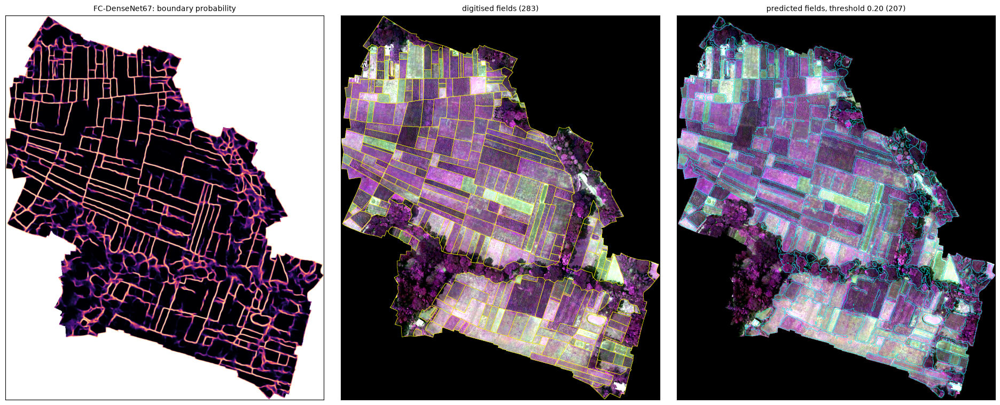

In [17]:
# Step 9. From boundary probability to georeferenced field polygons for the test site.
def polygons(site, prob, th, dil):
    """Fields = closed non-boundary regions of the thresholded probability (ed.boundary_to_instances),
    as polygons of at least 20 m², kept when they fall inside the digitised area of the site."""
    g = G[site]
    lab = ed.boundary_to_instances(prob, threshold=th, min_area_pixels=1, dilate_pixels=dil)
    fl, _ = ed._field_geodataframes(lab, prob, transform=g["T"], crs=g["crs"], min_area_m2=20)
    return fl[fl.representative_point().within(g["fields"].union_all())].copy()

def match(site, pred):
    """Best IoU of every digitised field with any predicted field (0 when nothing overlaps)."""
    ref = G[site]["fields"].reset_index(drop=True)
    inter = gpd.overlay(ref[["geometry"]].reset_index(names="ref"), pred[["field_id", "geometry"]], how="intersection")
    inter["a"] = inter.area
    best = inter.sort_values("a").groupby("ref").last()
    pg = pred.set_index("field_id").geometry
    return best.apply(lambda r: r.a / ref.geometry[r.name].union(pg[r.field_id]).area, axis=1).reindex(ref.index).fillna(0)

def prob_of(site):
    return ed.predict_boundary_probability(rgb(G[site]), MODELS[BEST], tile_size=TILE, overlap=64, batch_size=8,
                                           device=DEVICE, image_range=(0, 1))

# 1. The pixel threshold maximises boundary F1, but one gap in a boundary line merges two fields.
#    The polygon threshold and the dilation of the boundary mask are therefore chosen separately,
#    by object matching on Babuganj (Bangladesh, training site), and then applied to Chandpasha.
PROB = {s: prob_of(s) for s in ("babuganj", TEST)}
rows = []
for th in (0.1, 0.15, 0.2, 0.25, float(thr[BEST]), 0.5):
    for dil in (0, 1):
        iou = match("babuganj", polygons("babuganj", PROB["babuganj"], th, dil))
        rows.append({"threshold": th, "dilate (px)": dil, "IoU >= 0.5": (iou >= 0.5).mean(), "median IoU": iou.median()})
poly_sel = pd.DataFrame(rows).sort_values(["median IoU", "IoU >= 0.5"], ascending=False)
print("Babuganj: object matching of FC-DenseNet67 fields for polygon settings (best first)")
display(poly_sel.head(6).round(3).set_index(["threshold", "dilate (px)"]))
P_TH, P_DIL = poly_sel.iloc[0][["threshold", "dilate (px)"]]
P_DIL = int(P_DIL)

# 2. Chandpasha with the pixel threshold and with the selected polygon settings.
ref = TG["fields"].reset_index(drop=True)
summ, IOU = {"digitised": {"fields": len(ref), "median area (m²)": ref.area.median(), "mean area (m²)": ref.area.mean()}}, {}
for label, (th, dil) in {f"pixel threshold {float(thr[BEST]):.2f}, dilate 1": (float(thr[BEST]), 1),
                         f"selected on Babuganj: {P_TH:.2f}, dilate {P_DIL}": (P_TH, P_DIL)}.items():
    pred = polygons(TEST, PROB[TEST], th, dil)
    iou = IOU[label] = match(TEST, pred)
    summ[label] = {"fields": len(pred), "median area (m²)": pred.area.median(), "mean area (m²)": pred.area.mean(),
                   "IoU >= 0.5": (iou >= 0.5).mean(), "IoU >= 0.7": (iou >= 0.7).mean(), "median IoU": iou.median()}
display(pd.DataFrame(summ).T.round(2))

# 3. Save the probability raster (no-data outside the flight) and the selected polygons.
H_, W_ = TG["B"].shape
with rasterio.open(OUT / "chandpasha_boundary_probability.tif", "w", driver="GTiff", height=H_, width=W_, count=1,
                   dtype="float32", crs=TG["crs"], transform=TG["T"], compress="deflate", nodata=np.nan) as dst:
    dst.write(np.where(TG["ok"], PROB[TEST], np.nan).astype("float32"), 1)
pred.to_file(OUT / "chandpasha_predicted_fields.gpkg", layer="fields", driver="GPKG")
print("saved:", OUT / "chandpasha_boundary_probability.tif", "and", OUT / "chandpasha_predicted_fields.gpkg")

EXT = TG["extent"]
fig, ax = plt.subplots(1, 3, figsize=(19, 7.5))
ax[0].imshow(np.where(TG["ok"], PROB[TEST], np.nan), cmap="magma", vmin=0, vmax=1, extent=EXT)
ax[0].set_title(f"{BEST}: boundary probability")
ax[1].imshow(rgb(TG), extent=EXT); ref.boundary.plot(ax=ax[1], color="yellow", lw=0.4); ax[1].set_title(f"digitised fields ({len(ref)})")
ax[2].imshow(rgb(TG), extent=EXT); pred.boundary.plot(ax=ax[2], color="cyan", lw=0.4)
ax[2].set_title(f"predicted fields, threshold {P_TH:.2f} ({len(pred)})")
for a in ax:
    a.set_xlim(EXT[:2]); a.set_ylim(EXT[2:]); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Polygon settings.** On Babuganj, a low threshold (0.20) without dilating the boundary mask matches the digitised fields best (median IoU 0.67). The pixel-level threshold of 0.35 is too high for polygons: the lines it keeps are narrower and more often broken, and one gap merges two plots. Babuganj contains the training tiles, so its object scores are optimistic. They are used only to pick the two polygon settings, never to score.

**Chandpasha.**

- **Selected settings.** They give 207 fields against 283 digitised fields. 29 % of the digitised fields are matched with IoU ≥ 0.5 (15 % with IoU ≥ 0.7), and the median best IoU is 0.26.
- **Pixel threshold.** It would give 142 fields, 21 % matched, median IoU 0.15.

**Why the probability map is better than the polygons.** The probability map (left) traces nearly every bund, which is a much better result than the polygon scores suggest. The plots are tiny: a median of 317 m² is about 18 m x 18 m, or 36 x 36 pixels, of which the 1 m boundary band takes a large share. One missed segment merges neighbours, and a spurious line through a striped field splits one. Homestead tree cover (dark purple) is broken into irregular polygons. These lie outside the digitised plots and are not scored, but a real application would mask them first.

## Validation in the training sites vs the independent test site


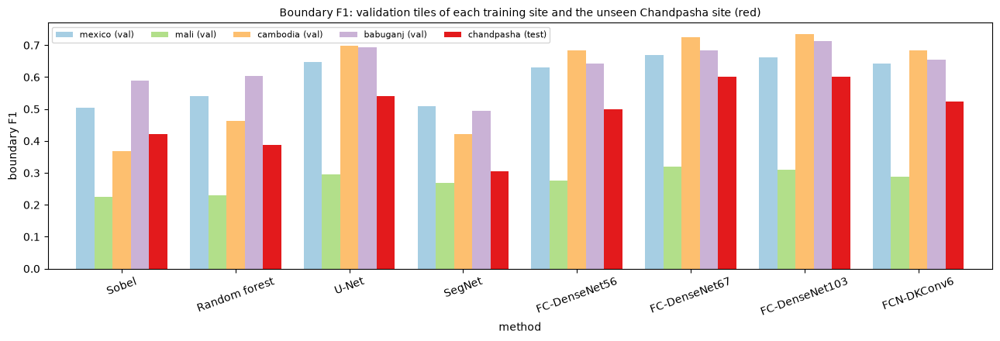

,validation (all four),Chandpasha (test),test - validation
method,,,
Roberts,0.327,0.314,-0.013
Sobel,0.389,0.422,0.033
Prewitt,0.390,0.424,0.034
Laplacian of Gaussian,0.320,0.300,-0.021
Canny,0.213,0.305,0.092
Random forest,0.423,0.387,-0.036
FCN-DKConv6,0.591,0.523,-0.068
U-Net,0.608,0.541,-0.067
SegNet,0.428,0.305,-0.123


In [18]:
# Step 10. Validation in the training sites vs the independent test site.
plot = val_f1[[c for c in val_f1.columns if c != "all four (val)"]].loc[["Sobel", "Random forest"] + nets]
ax = plot.plot.bar(figsize=(13, 4.5), width=0.8, color=["#a6cee3", "#b2df8a", "#fdbf6f", "#cab2d6", "#e31a1c"])
ax.set_ylabel("boundary F1"); ax.set_xticklabels(plot.index, rotation=20)
ax.set_title("Boundary F1: validation tiles of each training site and the unseen Chandpasha site (red)")
ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

gap = pd.DataFrame({"validation (all four)": val_f1["all four (val)"], "Chandpasha (test)": val_f1["chandpasha (test)"]})
gap["test - validation"] = gap["Chandpasha (test)"] - gap["validation (all four)"]
display(gap.loc[ORDER].round(3))

**Validation vs test.**

- **Learned methods** all score lower on Chandpasha than on the pooled validation tiles:
  - FC-DenseNet67 and FC-DenseNet103 lose 0.02 to 0.03;
  - U-Net, FCN-DKConv6 and FC-DenseNet56 lose 0.07 to 0.09;
  - the random forest loses 0.04 and SegNet 0.12.

  The validation tiles come from the same images, dates and landscapes as the training tiles, so they overstate how well a model transfers. The deeper dense networks transfer best.
- **Traditional detectors** score the same or *higher* on Chandpasha (Sobel and Prewitt +0.03, Canny +0.09). They learn nothing from the training sites. They gain because boundaries are a larger share of Chandpasha (15 %) than of the validation tiles (9 %), which raises boundary F1 for any detector, and because the Bangladesh bunds are sharp in the drone image.
- **Same country, other site.** Babuganj and Chandpasha share a country and a sensor, yet FC-DenseNet67 drops from 0.68 on the Babuganj validation tiles to 0.60 on Chandpasha. Even within one district, a new site costs some accuracy.

## Discussion

### What the independent test shows

- **Ranking.** It is the same as in the paper and in 09_10_03: networks with skip connections or dense blocks > random forest ≈ traditional detectors > SegNet. On the unseen Chandpasha site, FC-DenseNet67 and FC-DenseNet103 reach boundary F1 0.60 (0.81 with 1 m tolerance) and AUC 0.88. That is higher than the 0.41 to 0.46 of 09_10_03, which trained on 45 tiles of one scene; here there are 380 tiles from four countries and finer images.
- **Depth.** In 09_10_03, depth did not matter. With more varied training data, the deeper FC-DenseNets now beat FC-DenseNet56 by 0.10 and U-Net by 0.06 on the test site, and they lose the least between validation and test.
- **Pooling countries works only with local data.** A model trained in Mexico, Mali and Cambodia alone fails in Bangladesh (F1 0.31, below Sobel). Fourteen Bangladesh tiles from a neighbouring site raise it to 0.56, and all four sites together give 0.60. For a new region, digitising a few local tiles is worth more than adding distant countries.

### Why the sites differ

- **Mali.** Its 2 m image cannot show a 1 m boundary. Every method scores at most 0.32 there, and its tiles (about half of the training set) mostly teach the networks what large fields look like.
- **Bangladesh.** The drone images are very fine (0.06 to 0.1 m). Averaging them to 0.5 m keeps the bunds sharp, which is why even Sobel does well on Chandpasha.
- **Mexico and Cambodia.** Mexico's terrace edges are long and curved, and Cambodia's paddy bunds are straight and wide. Both are learned well (validation F1 up to 0.67 and 0.73).

### Limitations

- **One test site.** Chandpasha holds 283 digitised fields (15 ha). The order of the two best networks (0.601 vs 0.600) is a tie. A second independent site in another country would show whether the result holds beyond Bangladesh.
- **Per-site normalisation.** Each image is stretched by its own percentiles. This is label-free and works for a whole new image, but not for a small clip with an unusual brightness distribution.
- **Labels.** Lines were closed into fields. Where a digitiser left a gap, two fields became one, and where a frame line was drawn, a background face was dropped (Step 1). Some real bunds were not digitised, which lowers precision for every method alike.
- **Polygons.** Polygon settings were chosen on Babuganj, which also contributed training tiles. Object matching on Chandpasha (median IoU 0.26) is far below what the probability map shows. Gap closing, a cropland mask and an instance-segmentation model would be the next steps.
- **Budget.** 30 epochs and a single seed. Differences below about 0.02 F1 should not be read as real.

### Summary

- **Design.** Field-boundary detectors were trained on one site each from Mexico, Mali, Cambodia and Bangladesh, and tested on a second Bangladesh site that played no part in any choice. Labels, tiles, metrics and models come from `geolattice.rsense.edge_detectors`, as in 09_10_03.
- **Test boundary F1 on Chandpasha:**
  - FC-DenseNet67/103: 0.60 (AUC 0.88; 0.81 with 1 m tolerance);
  - U-Net 0.54; FCN-DKConv6 0.52; FC-DenseNet56 0.50;
  - Prewitt and Sobel 0.42; random forest 0.39; SegNet 0.31.
- **Training data.** Data from the target country is essential: the same network trained without Bangladesh reaches 0.31, with Babuganj alone 0.56, with all four sites 0.60.
- **Validation vs test.** Validation tiles from the training images overstate transfer by 0.02 to 0.12 F1 for learned methods, so an independent site is needed to judge a field-boundary model.
- **Outputs.** The boundary probability and 207 predicted field polygons for Chandpasha are saved in `outputs/edge_detection_global/`.

### References

- Yang, R., Ahmed, Z. U., Schulthess, U. C., Kamal, M., & Rai, R. (2020). Detecting functional field units from satellite images in smallholder farming systems using a deep learning based computer vision approach: A case study from Bangladesh. *Remote Sensing Applications: Society and Environment*, 20, 100413.
- Badrinarayanan, V., Kendall, A., & Cipolla, R. (2017). SegNet: A deep convolutional encoder-decoder architecture for image segmentation. *IEEE TPAMI*, 39(12), 2481-2495.
- Jégou, S., Drozdzal, M., Vazquez, D., Romero, A., & Bengio, Y. (2017). The one hundred layers tiramisu: Fully convolutional DenseNets for semantic segmentation. *CVPR Workshops*.
- Persello, C., & Stein, A. (2017). Deep fully convolutional networks for the detection of informal settlements in VHR images. *IEEE GRSL*, 14(12), 2325-2329.
- Ronneberger, O., Fischer, P., & Brox, T. (2015). U-Net: Convolutional networks for biomedical image segmentation. *MICCAI*.
- Canny, J. (1986). A computational approach to edge detection. *IEEE TPAMI*, 8(6), 679-698.
